In [2]:
from openfc.components.fuelingSystem import FuelingSystem
from openfc.components.component import Component
from openfc.components.plasma import Plasma
from openfc.components.breedingBlanket import BreedingBlanket
from openfc.componentMap import ComponentMap
from matplotlib import pyplot as plt
from openfc.simulate import Simulate
import numpy as np
from openfc.tools.utils import visualize_connections

LAMBDA = 1.73e-9 # Decay constant for tritium
AF = 0.7
N_burn = 9.3e-7 * AF # Tritium burn rate in the plasma adjusted for AF - THIS IS IMPACTING THE RESERVE INVENTORY
TBR = 1.073

# Residence times
tau_bb = 1.25 * 3600
tau_fc =  3600

tau_ofc = 2 * 3600
tau_ifc = 5 * 3600

tau_tes = 24 * 3600
tau_HX = 1 * 3600
tau_FW = 1000
tau_div = 1000
tau_ds = 3600
tau_vp = 600
tau_iss = 3 * 3600
tau_membrane = 100

# Flow fractions
fp_fw = 1e-4
fp_div = 1e-4
f_dir = 0.3
f_iss_ds = 0.1
tes_efficiency = 0.9
hx_to_fw = 0.33
hx_to_div = 0.33
hx_to_ds = 1e-4
hx_to_BB = 1 - hx_to_fw - hx_to_div - hx_to_ds

# General input parameters
I_startup = 1.1
TBE = 0.02
final_time = 2.1 * 3600 * 24 * 365 # NB: longer than doubling time
q = 0.25
t_res = 24 * 3600
I_reserve = N_burn/AF / TBE * q * t_res


# Define components
fueling_system = FuelingSystem("Fueling System", N_burn, TBE, initial_inventory=I_startup)
BB = BreedingBlanket("BB", tau_bb, initial_inventory=0, N_burn = N_burn, TBR = TBR)
FW = Component("FW", residence_time = tau_FW)
divertor = Component("Divertor", residence_time = tau_div)
fuel_cleanup = Component("Fuel cleanup", tau_fc)
plasma = Plasma("Plasma", N_burn, TBE, fp_fw=fp_fw, fp_div=fp_div)   
TES = Component("TES", residence_time = tau_tes)
HX = Component("HX", residence_time = tau_HX)
DS = Component("DS", residence_time = tau_ds)
VP = Component("VP", residence_time = tau_vp)
ISS = Component("ISS", residence_time = tau_iss)
membrane = Component("Membrane", residence_time = tau_membrane)

# Define ports
port1 = fueling_system.add_output_port("Fueling to Plasma")
port2 = plasma.add_input_port("Port 2", incoming_fraction= (1 - fp_div - fp_fw))
port3 = plasma.add_output_port("Plasma to VP")
port4 = fuel_cleanup.add_input_port("Port 4", incoming_fraction= 1 - f_dir)
port5 = fuel_cleanup.add_output_port("fuel_cleanup to ISS")
port6 = BB.add_output_port("OFC to TES")
port7 = fueling_system.add_input_port("Port 7", incoming_fraction=1 - f_iss_ds)
port8 = fuel_cleanup.add_input_port("Port 8")
port9 = TES.add_output_port("TES to Membrane")
port10 = TES.add_output_port("TES to HX")
port11 = TES.add_input_port("Port 11")
port12 = fueling_system.add_input_port("Port 12")
port13 = HX.add_input_port("Port 13", incoming_fraction= 1 - tes_efficiency)
port14 = HX.add_output_port("HX to BB")
port15 = BB.add_input_port("Port 15", incoming_fraction= hx_to_BB)
port16 = FW.add_input_port("Port 16", incoming_fraction=hx_to_fw)
port17 = FW.add_output_port("FW to BB")
port18 = divertor.add_input_port("Port 18", incoming_fraction=hx_to_div)
port19 = divertor.add_output_port("Divertor to FW")
port20 = HX.add_output_port("HX to FW")
port21 = HX.add_output_port("HX to div")
port22 = BB.add_input_port("Port 22")
port23 = BB.add_input_port("Port 23")
port24 = DS.add_input_port("Port 24", incoming_fraction=hx_to_ds)
port25 = DS.add_output_port("DS to ISS")
port26 = HX.add_output_port("HX to DS")
port27 = fuel_cleanup.add_input_port("Port 27")  
port28 = VP.add_input_port("Port 28")
port29 = VP.add_output_port("VP to fuel_cleanup")
port30 = VP.add_output_port("VP to Fueling System")
port31 = fueling_system.add_input_port("Port 31", incoming_fraction=f_dir)
port32 = ISS.add_input_port("Port 32")
port33 = ISS.add_input_port("Port 33")
port34 = ISS.add_output_port("ISS to fueling system")
port35 = DS.add_input_port("Port 35", incoming_fraction=f_iss_ds)
port36 = ISS.add_output_port("ISS to DS")
port37 = membrane.add_input_port("Port 37", incoming_fraction = tes_efficiency)
port38 = membrane.add_output_port("Membrane to fueling system")
port39 = fueling_system.add_output_port("Fueling to FW")
port40= fueling_system.add_output_port("Fueling to div")
port41 = FW.add_input_port("Port 41", incoming_fraction=fp_fw)
port42 = divertor.add_input_port("Port 42", incoming_fraction=fp_div)

# Add components to component map
component_map = ComponentMap()
component_map.add_component(fueling_system)
component_map.add_component(BB)
component_map.add_component(fuel_cleanup)
component_map.add_component(plasma)
component_map.add_component(TES)
component_map.add_component(HX)
component_map.add_component(FW)
component_map.add_component(divertor)
component_map.add_component(DS)
component_map.add_component(VP)
component_map.add_component(ISS)
component_map.add_component(membrane)

# Connect ports
component_map.connect_ports(fueling_system, port1, plasma, port2)
component_map.connect_ports(plasma, port3, VP, port28)
component_map.connect_ports(VP, port29, fuel_cleanup, port4)
component_map.connect_ports(VP, port30, fueling_system, port31)
component_map.connect_ports(fuel_cleanup, port5, ISS, port32)
component_map.connect_ports(BB, port6, TES, port11)
component_map.connect_ports(TES, port9, membrane, port37)
component_map.connect_ports(membrane, port38, fueling_system, port12)
component_map.connect_ports(TES, port10, HX, port13)
component_map.connect_ports(HX, port14, BB, port15)
component_map.connect_ports(HX, port20, FW, port16)
component_map.connect_ports(HX, port21, divertor, port18)
component_map.connect_ports(FW, port17, BB, port22)
component_map.connect_ports(divertor, port19, BB, port23)
component_map.connect_ports(HX, port26, DS, port24)
component_map.connect_ports(DS, port25, ISS, port33)
component_map.connect_ports(ISS, port34, fueling_system, port7)
component_map.connect_ports(ISS, port36, DS, port35)
component_map.connect_ports(fueling_system, port39, FW, port41)
component_map.connect_ports(fueling_system, port40, divertor, port42)


Component: Fueling System
  Port: Fueling to Plasma -> Connected Component: Plasma, Connected Port: Port 2
  Port: Port 31 -> Connected Component: VP, Connected Port: VP to Fueling System
  Port: Port 12 -> Connected Component: Membrane, Connected Port: Membrane to fueling system
  Port: Port 7 -> Connected Component: ISS, Connected Port: ISS to fueling system
  Port: Fueling to FW -> Connected Component: FW, Connected Port: Port 41
  Port: Fueling to div -> Connected Component: Divertor, Connected Port: Port 42
Component: Plasma
  Port: Port 2 -> Connected Component: Fueling System, Connected Port: Fueling to Plasma
  Port: Plasma to VP -> Connected Component: VP, Connected Port: Port 28
Component: VP
  Port: Port 28 -> Connected Component: Plasma, Connected Port: Plasma to VP
  Port: VP to fuel_cleanup -> Connected Component: Fuel cleanup, Connected Port: Port 4
  Port: VP to Fueling System -> Connected Component: Fueling System, Connected Port: Port 31
Component: Fuel cleanup
  Port

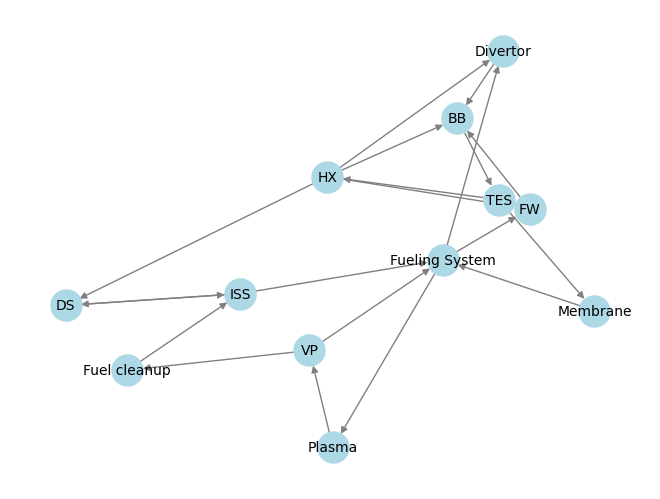

In [3]:
component_map.print_connected_map()
visualize_connections(component_map)

In [4]:
print(f'Startup inventory is: {fueling_system.tritium_inventory}')
simulation = Simulate(dt=0.01, dt_max = 1000, final_time=final_time, I_reserve=I_reserve, component_map=component_map, max_simulations=2)
t, y = simulation.run()
# np.savetxt('tritium_inventory.txt', [t,y], delimiter=',')


Startup inventory is: 1.1
Initial inventories = [1.1, 0, 1e-12, 1e-12, 1e-12, 1e-12, 1e-12, 1e-12, 1e-12, 1e-12, 1e-12, 1e-12] kg
I_0 = 1.1 kgror = 6.681858751890821e-12, dt = 0.01, dt_new = 1496.589552595708
Doubling time: 1.5046429294361114 

Startup inventory is: 1.1 

Error: Tritium inventory in Fueling System is below zero. Difference is -0.33870953906053713 kg
Updated I_startup to 1.4387095390605373
Initial inventories = [np.float64(1.4387095390605373), 0, 1e-12, 1e-12, 1e-12, 1e-12, 1e-12, 1e-12, 1e-12, 1e-12, 1e-12, 1e-12] kg
I_0 = 1.4387095390605373 kgError = 1.5198475220995383e-06, dt = 326.7417265756738, dt_new = 214.983228136141102897
Doubling time: 1.8852556271462042 

Startup inventory is: 1.4387095390605373 



/tmp/ipykernel_35493/4285223596.py:12: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/home/alessmor/anaconda3/envs/fuelcycle-env/lib/python3.14/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


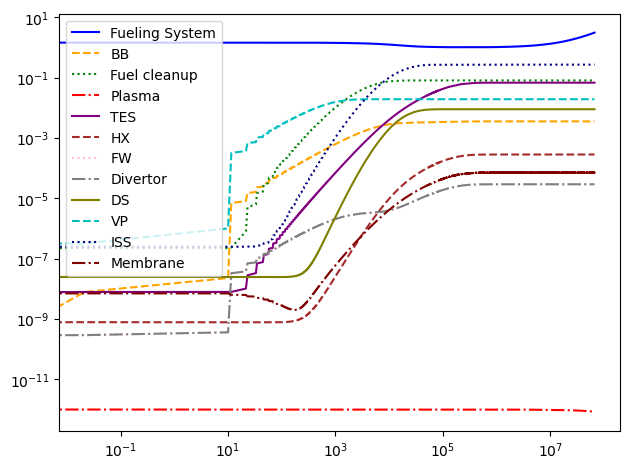

Component inventories: dict_keys(['Fueling System', 'BB', 'Fuel cleanup', 'Plasma', 'TES', 'HX', 'FW', 'Divertor', 'DS', 'VP', 'ISS', 'Membrane']): [3.08025316e+00 3.52453490e-03 8.03524196e-02 8.45738563e-13
 6.76541922e-02 2.81862526e-04 2.90894389e-05 2.90894389e-05
 8.92584723e-03 1.91335608e-02 2.67803017e-01 7.07066437e-05]

Component: Fueling System, inflow: 0.0000 kg/s, outflow: 0.0000 kg/s
Component: BB, inflow: 0.0000 kg/s, outflow: 0.0000 kg/s
Component: Fuel cleanup, inflow: 0.0000 kg/s, outflow: 0.0000 kg/s
Component: Plasma, inflow: 0.0000 kg/s, outflow: 0.0000 kg/s
Component: TES, inflow: 0.0000 kg/s, outflow: 0.0000 kg/s
Component: HX, inflow: 0.0000 kg/s, outflow: 0.0000 kg/s
Component: FW, inflow: 0.0000 kg/s, outflow: 0.0000 kg/s
Component: Divertor, inflow: 0.0000 kg/s, outflow: 0.0000 kg/s
Component: DS, inflow: 0.0000 kg/s, outflow: 0.0000 kg/s
Component: VP, inflow: 0.0000 kg/s, outflow: 0.0000 kg/s
Component: ISS, inflow: 0.0000 kg/s, outflow: 0.0000 kg/s
Compon

In [5]:

combinations = [
    ('b', '-'), ('orange', '--'), ('g', ':'), ('r', '-.'), 
    ('purple', '-'), ('brown', '--'), ('pink', ':'), ('gray', '-.'), 
    ('olive', '-'), ('c', '--'), ('navy', ':'), ('maroon', '-.')
]

fig,ax = plt.subplots()
for i, (color, linestyle) in enumerate(combinations):
    ax.loglog(t, np.array(y)[:,i], color=color, linestyle=linestyle)
# ax.loglog(t, y)
ax.legend(component_map.components.keys())
fig.tight_layout()

plt.show()

print(f"Component inventories: {component_map.components.keys()}: {y[-1]}\n")

for component in component_map.components.values():
    print(f"Component: {component.name}, inflow: {component.inflow[-1]:.4f} kg/s, outflow: {component.outflow[-1]:.4f} kg/s")
